In [1]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
%matplotlib inline

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.compose import ColumnTransformer
from scipy.stats import skew, boxcox

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor 
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("diamonds.csv")

In [3]:
df.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


In [5]:
df = df.drop("Unnamed: 0", axis=1)

df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [6]:
len(df[df["x"] == 0]), len(df[df["y"] == 0]), len(df[df["z"] == 0])

(8, 7, 20)

In [7]:
for i in ["x", "y", "z"]:
    df = df.drop(df[df[i] == 0].index)

In [8]:
num_cols_price = df.select_dtypes(include=["float64", "int64"]).columns.drop("price")

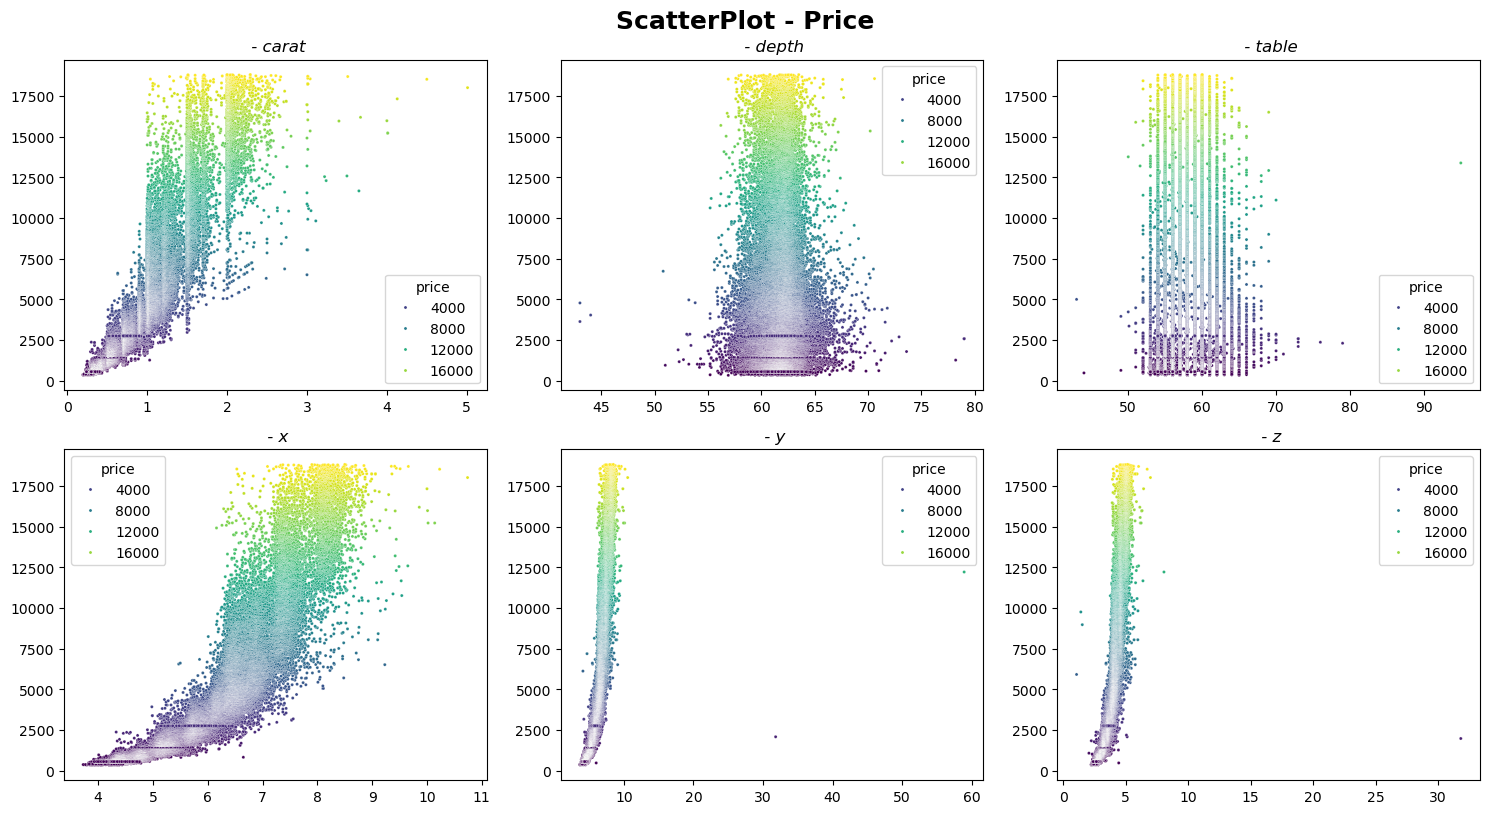

In [9]:
def scatter_plot(df, num_cols, title_prefix=""):
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15,12))
    plt.suptitle("ScatterPlot - Price", fontsize=18, fontweight="bold")
    
    for i,col in enumerate(num_cols):
        row = i // 3
        col_id = i % 3
        ax = axes[row, col_id]
        sns.scatterplot(data=df, x=col, y="price", hue="price", palette="viridis", ax=ax, s=5)
        ax.set_title(f"{title_prefix} - {col}", fontsize=12, style="italic")
        ax.set_xlabel("")
        ax.set_ylabel("")
        
    axes = axes.flatten()
    for j in range(len(num_cols), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

scatter_plot(df, num_cols_price)

In [10]:
num_cols = df.select_dtypes(include=["float64", "int64"]).columns
cat_cols = df.select_dtypes(include=["object"]).columns

In [11]:
def find_outlier_iqr(df, threshold=1.5):
    outlier_summary = {}

    num_cols = df.select_dtypes(include=["float64", "int64"]).columns

    for i, col in enumerate(num_cols):
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - threshold * IQR
        upper_bound = Q3 + threshold * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

        outlier_summary[col] = {
            "Outlier Count" : outliers.shape[0],
            "Outliner Percentange" : (outliers.shape[0] / df.shape[0]) * 100,
            "lower Bound" : lower_bound,
            "Upper Bound" : upper_bound
        }

    return pd.DataFrame(outlier_summary)

In [12]:
find_outlier_iqr(df, threshold=1.5)

,carat,depth,table,price,x,y,z
Outlier Count,1883.000000,2543.000000,604.000000,3532.000000,24.00000,22.000000,29.000000
Outliner Percentange,3.492211,4.716246,1.120178,6.550445,0.04451,0.040801,0.053783
lower Bound,-0.560000,58.750000,51.500000,-5612.375000,1.96500,1.990000,1.215000
Upper Bound,2.000000,64.750000,63.500000,11884.625000,9.28500,9.270000,5.735000


In [13]:
def remove_outlier_from_column(df, target_cols, threshold=0.5):
    df_clean = df.select_dtypes(include=["float64", "int64"]).copy()

    Q1 = df_clean[target_cols].quantile(0.25)
    Q3 = df_clean[target_cols].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - threshold * IQR
    upper_bound = Q3 + threshold * IQR

    df_clean = df_clean[(df_clean[target_cols] >= lower_bound) & (df_clean[target_cols] <= upper_bound)]

    return df_clean.copy()

In [14]:
df_new = remove_outlier_from_column(df, num_cols)
for col in df_new:
    df_new[col] = df_new[col].fillna(df_new[col].median())

In [15]:
df_final = df_new.merge(df.select_dtypes(include="object"), left_index=True, right_index=True)
df_final.head()

,carat,depth,table,price,x,y,z,cut,color,clarity
0,0.23,61.5,55.0,326.0,3.95,3.98,2.43,Ideal,E,SI2
1,0.21,61.9,57.0,326.0,3.89,3.84,3.42,Premium,E,SI1
2,0.23,61.9,57.0,327.0,4.05,4.07,3.42,Good,E,VS1
3,0.29,62.4,58.0,334.0,4.20,4.23,2.63,Premium,I,VS2
4,0.31,61.9,58.0,335.0,4.34,4.35,2.75,Good,J,SI2


In [16]:
X = df_final.drop("price", axis=1)
y = df_final["price"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=42)

In [17]:
num_cols = df_final.select_dtypes(include=["float64", "int64"]).columns

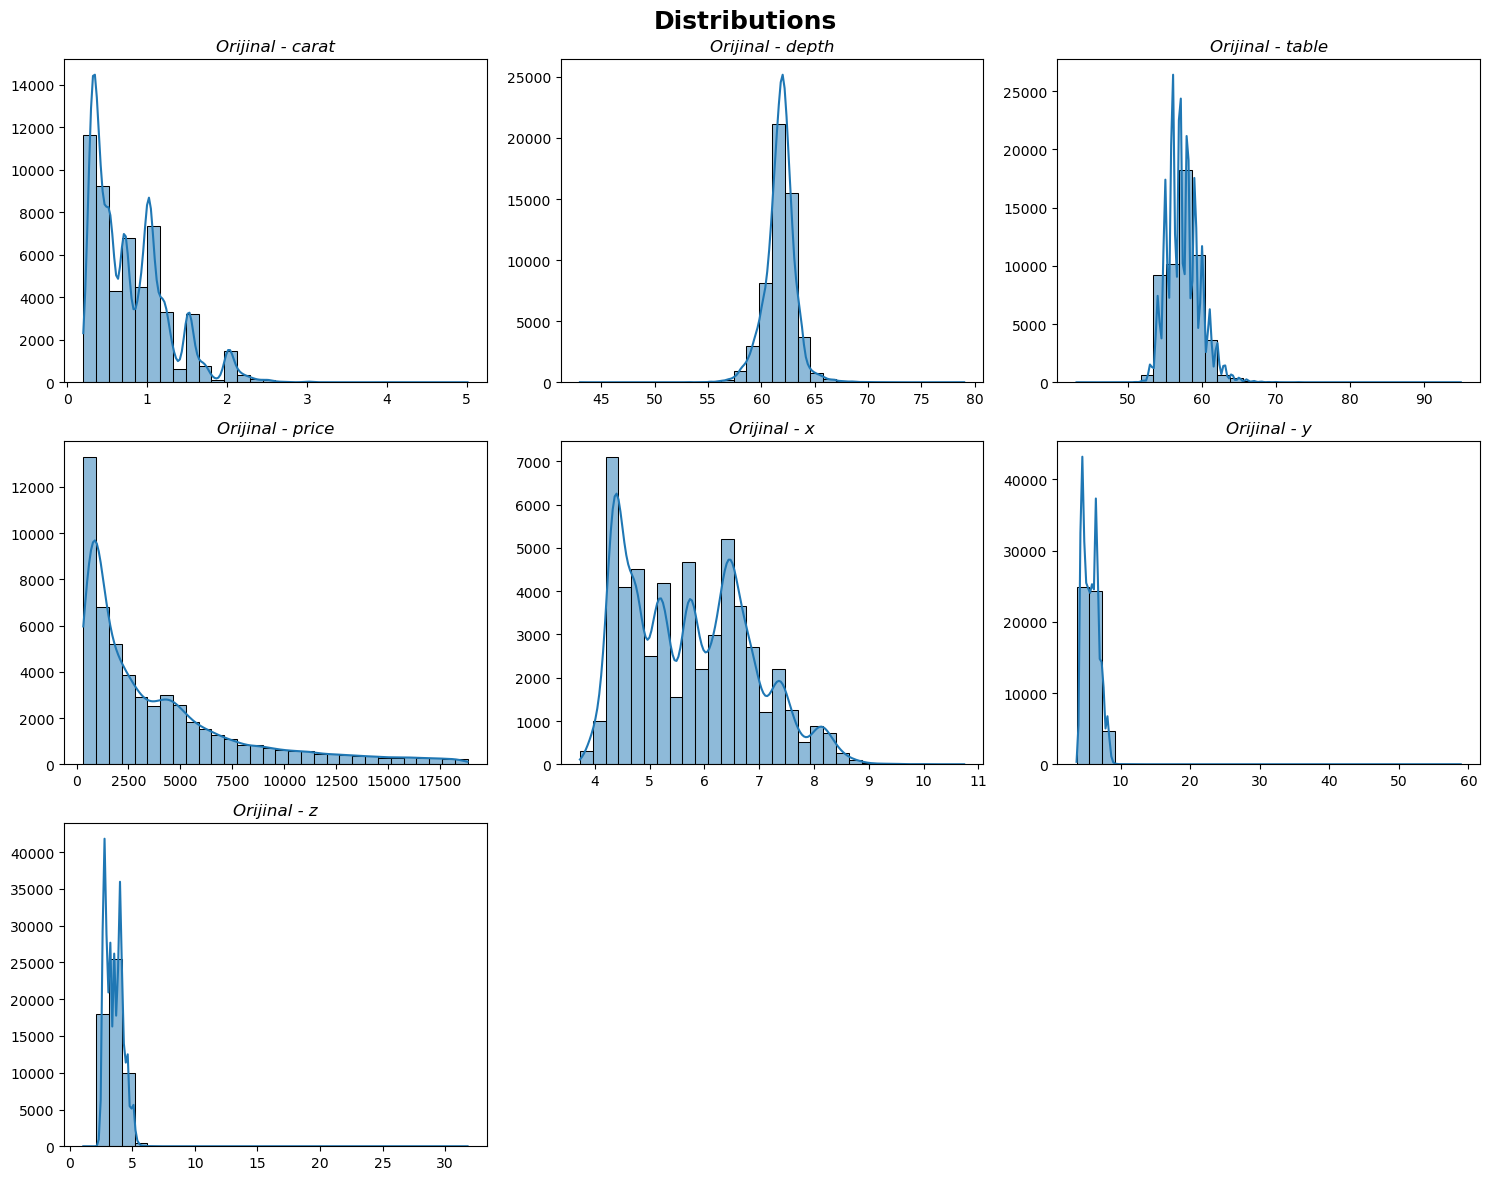

In [18]:
def hist_plot(df, num_cols, title_prefix="", suptitle_color="black"):
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15,12))
    plt.suptitle(f"Distributions", fontsize=18, fontweight="bold", color=suptitle_color)
    
    for i, col in enumerate(num_cols):
        row = i // 3
        col_idx = i % 3
        ax = axes[row, col_idx]
        sns.histplot(data=df, x=col, ax=ax, kde=True, bins=30)
        ax.set_title(f"{title_prefix} - {col}", fontsize=12, style="italic")
        ax.set_xlabel("")
        ax.set_ylabel("")

    
    axes = axes.flatten()
    for j in range(len(num_cols), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

hist_plot(df, num_cols, title_prefix="Orijinal")

In [19]:
df_final_skew = pd.DataFrame(df_final[num_cols].apply(skew).sort_values(ascending=False), columns=["skew"])
df_final_skew

,skew
price,1.071807
carat,0.524426
table,0.305491
z,0.173625
y,0.170809
x,0.168849
depth,-0.250729


In [20]:
num_pipe = Pipeline([
    ("yeojohnson", PowerTransformer(method="yeo-johnson")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols_price)
])

pipe_y = Pipeline([
    ("yeojohnson", PowerTransformer(method="yeo-johnson"))    
])

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
X_train_transformed = pd.DataFrame(X_train_preprocessed, columns=num_cols_price)
X_test_transformed = pd.DataFrame(X_test_preprocessed, columns=num_cols_price)

y_train = pd.DataFrame(y_train, columns=["price"])
y_test = pd.DataFrame(y_test, columns=["price"])

y_train_preprocessed = pipe_y.fit_transform(y_train)
y_test_preprocessed = pipe_y.transform(y_test)
y_train_transformed = pd.DataFrame(y_train_preprocessed, columns=["price"])
y_test_transformed = pd.DataFrame(y_test_preprocessed, columns=["price"])

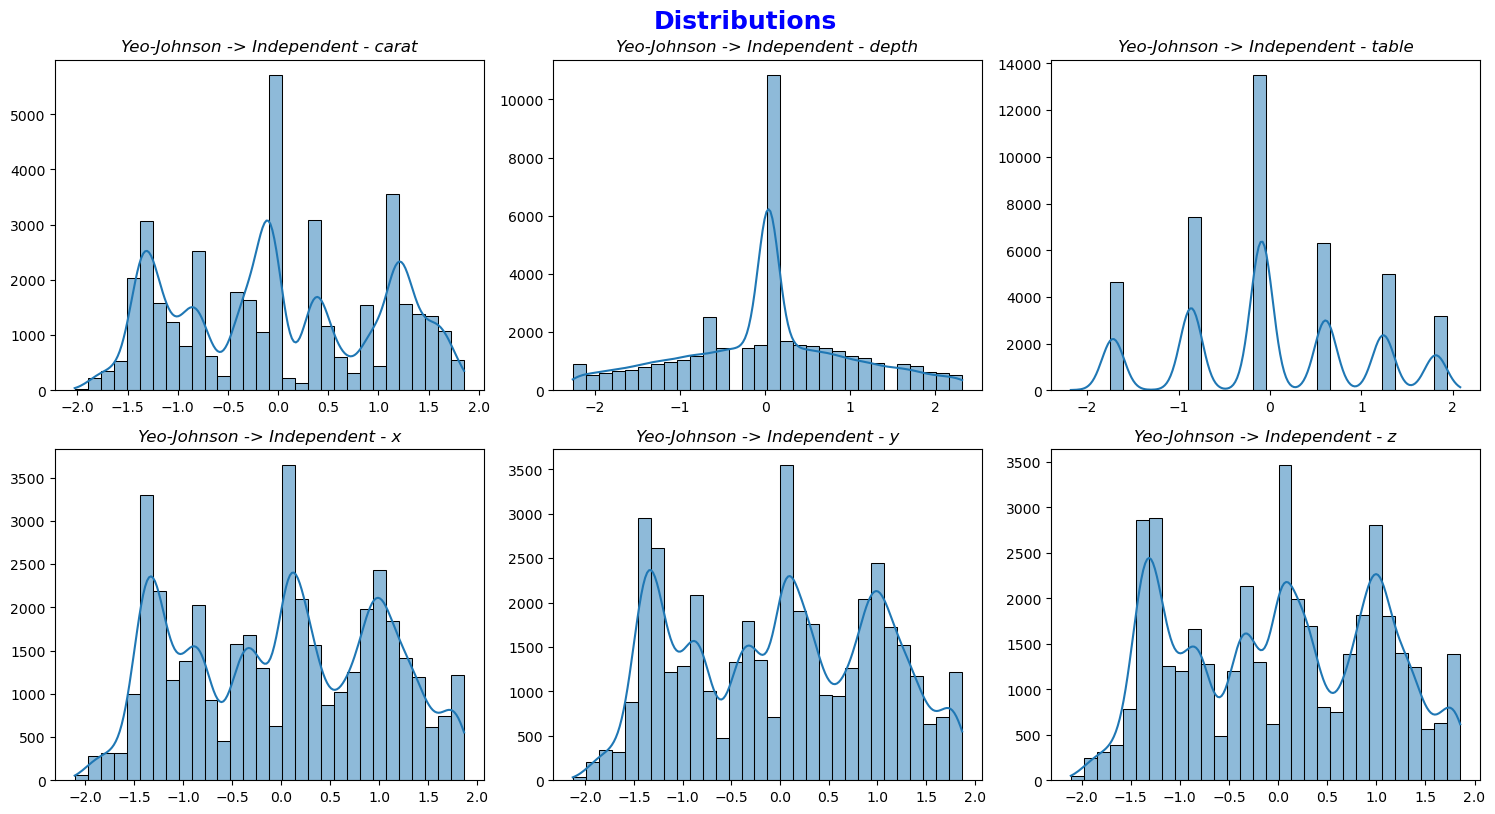

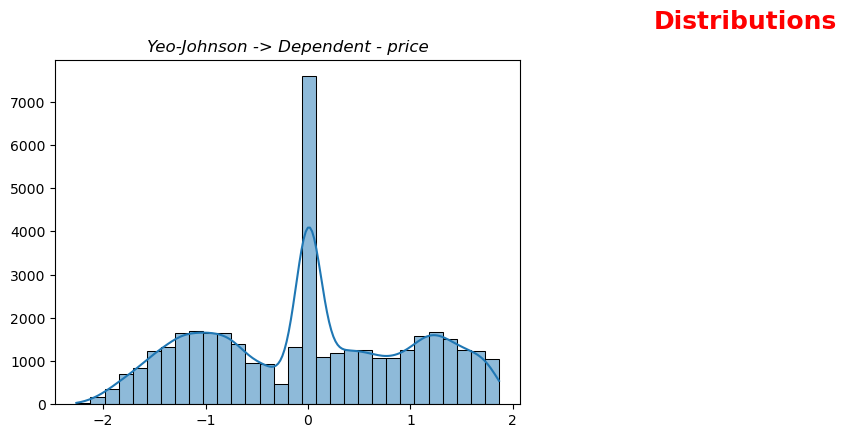

In [21]:
hist_plot(X_train_transformed, num_cols_price, "Yeo-Johnson -> Independent", suptitle_color="b")
hist_plot(y_train_transformed, ["price"], "Yeo-Johnson -> Dependent", suptitle_color="r")

In [22]:
preprocessor_1 = ColumnTransformer([
    ("cat",OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

X_train_cat = preprocessor_1.fit_transform(X_train)
X_test_cat = preprocessor_1.transform(X_test)

onehot_cols = preprocessor_1.get_feature_names_out()

X_train_cat_df = pd.DataFrame(X_train_cat.toarray(), columns=onehot_cols)
X_test_cat_df = pd.DataFrame(X_test_cat.toarray(), columns=onehot_cols)

In [23]:
X_train_final = X_train_transformed.merge(X_train_cat_df, left_index=True, right_index=True)

In [24]:
X_test_final = X_test_transformed.merge(X_test_cat_df, left_index=True, right_index=True)

In [25]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(true, predicted)

    return r2, rmse, mae 

In [26]:
models = {
    "linear_regression" : LinearRegression(),
    "lasso" : Lasso(),
    "ridge" : Ridge(),
    "svm" : SVR(),
    "naive" : GaussianNB(),
    "knn" : KNeighborsRegressor(),
    "tree" : DecisionTreeRegressor(),
    "rf" : RandomForestRegressor(),
    "ada" : AdaBoostRegressor(),
    "Gradient" : GradientBoostingRegressor(),
    "xgb" : XGBRegressor(),
    "lgbm" : LGBMRegressor(verbosity=-1)
}

for i in range(len(list(models))):
    model = list(models.values())[i]

    model.fit(X_train_final, y_train)
    y_train_pred = model.predict(X_train_final)
    y_test_pred = model.predict(X_test_final)

    model_train_r2, model_train_rmse, model_train_mae = evaluate_model(y_train, y_train_pred)
    model_test_r2, model_test_rmse, model_test_mae = evaluate_model(y_test, y_test_pred)

    print(list(models.keys())[i])
    print("Model Performans for Traning Set")
    print("Root Mean Squared Error: ", model_train_rmse)
    print("Mean Absolute Error: ", model_train_mae)
    print("R2 Score: ", model_train_r2)

    print("-"*50)
    
    print("Model Performans for Test Set")
    print("Root Mean Squared Error: ", model_test_rmse)
    print("Mean Absolute Error: ", model_test_mae)
    print("R2 Score: ", model_test_r2)

    print("-"*50)
    print("\n")

linear_regression
Model Performans for Traning Set
Root Mean Squared Error:  1048.3697663425307
Mean Absolute Error:  689.4425636686742
R2 Score:  0.65381439713622
--------------------------------------------------
Model Performans for Test Set
Root Mean Squared Error:  1033.8922185896306
Mean Absolute Error:  679.8235196086049
R2 Score:  0.6587098625363202
--------------------------------------------------


lasso
Model Performans for Traning Set
Root Mean Squared Error:  1048.5165861123178
Mean Absolute Error:  691.1373372997392
R2 Score:  0.6537174266756175
--------------------------------------------------
Model Performans for Test Set
Root Mean Squared Error:  1034.3553298717025
Mean Absolute Error:  681.5217307685746
R2 Score:  0.6584040459161149
--------------------------------------------------


ridge
Model Performans for Traning Set
Root Mean Squared Error:  1048.3697700529606
Mean Absolute Error:  689.4584925314108
R2 Score:  0.6538143946857536
------------------------------